# 🎬 Tip-of-the-Tongue Movie RAG

Find a movie from a vague description and answer questions about its plot, with cited sources.

**Pipeline**

```
Movie plots → Validation & cleaning → Chunking → Indexing (BM25 + embeddings + knowledge graph)
           → Query analysis → Hybrid retrieval → Grounded answer with citations
```

In [1]:
%pip install -q kaggle sentence-transformers transformers sentencepiece sacremoses datasets networkx pandas matplotlib einops

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 867.8/867.8 kB 12.6 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [2]:
import ast, json, math, random, re, time
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import requests

DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
CACHE_DIR = Path("cache"); CACHE_DIR.mkdir(exist_ok=True)

N_MOVIES = 10_000
N_TASK_A = 300
N_TASK_B = 300
DEFAULT_MODEL = "intfloat/multilingual-e5-small"
TOP_K = 10
SEED = 42
random.seed(SEED); np.random.seed(SEED)

## 1. Download

In [3]:
import subprocess
for slug in ["jrobischon/wikipedia-movie-plots", "thedevastator/duorc-a-dataset-of-movie-plots"]:
    target = DATA_DIR / slug.split("/")[1]
    if target.exists() and any(target.iterdir()):
        print("already have", slug); continue
    target.mkdir(parents=True, exist_ok=True)
    res = subprocess.run(["kaggle", "datasets", "download", "-d", slug, "-p", str(target), "--unzip"],
                         capture_output=True, text=True)
    print(slug, "->", "ok" if res.returncode == 0 else res.stderr.strip()[:300])

for p in sorted(DATA_DIR.rglob("*.csv")):
    print(f"{p}  ({p.stat().st_size / 1e6:.1f} MB)")

jrobischon/wikipedia-movie-plots -> ok
thedevastator/duorc-a-dataset-of-movie-plots -> ok
data/duorc-a-dataset-of-movie-plots/ParaphraseRC_test.csv  (115.2 MB)
data/duorc-a-dataset-of-movie-plots/ParaphraseRC_train.csv  (496.7 MB)
data/duorc-a-dataset-of-movie-plots/ParaphraseRC_validation.csv  (106.5 MB)
data/duorc-a-dataset-of-movie-plots/SelfRC_test.csv  (49.1 MB)
data/duorc-a-dataset-of-movie-plots/SelfRC_train.csv  (239.5 MB)
data/duorc-a-dataset-of-movie-plots/SelfRC_validation.csv  (51.6 MB)
data/wikipedia-movie-plots/wiki_movie_plots_deduped.csv  (81.2 MB)


## 2. Document validation & quality scoring

In [4]:
movie_csv = next((DATA_DIR / "wikipedia-movie-plots").rglob("*.csv"))
raw = pd.read_csv(movie_csv)
raw = raw.rename(columns={"Release Year": "year", "Title": "title", "Origin/Ethnicity": "origin",
                          "Director": "director", "Cast": "cast", "Genre": "genre",
                          "Wiki Page": "url", "Plot": "plot"})
print(raw.shape); raw.head(3)

(34886, 8)


,year,title,origin,director,cast,genre,url,plot
0,1901,Kansas Saloon Smashers,American,Unknown,NaN,unknown,https://en.wikipedia.org/wiki/Kansas_Saloon_Sm...,"A bartender is working at a saloon, serving dr..."
1,1901,Love by the Light of the Moon,American,Unknown,NaN,unknown,https://en.wikipedia.org/wiki/Love_by_the_Ligh...,"The moon, painted with a smiling face hangs ov..."
2,1901,The Martyred Presidents,American,Unknown,NaN,unknown,https://en.wikipedia.org/wiki/The_Martyred_Pre...,"The film, just over a minute long, is composed..."


In [5]:
MOJIBAKE = re.compile(r"(â€|Ã©|Ã¨|Ã¢|Â )")
CITE = re.compile(r"\[\d+\]|\[citation needed\]|\[edit\]", re.I)

def fix_mojibake(s):
    if not MOJIBAKE.search(s):
        return s, False
    try:
        return s.encode("cp1252").decode("utf-8"), True
    except (UnicodeEncodeError, UnicodeDecodeError):
        return s, False

def clean_plot(s):
    s = "" if pd.isna(s) else str(s)
    s, fixed = fix_mojibake(s)
    n_cites = len(CITE.findall(s))
    s = CITE.sub("", s).replace("\r\n", "\n").replace("\r", "\n")
    s = re.sub(r"[ \t]+", " ", s)
    s = re.sub(r"\n\s*\n+", "\n\n", s).strip()
    return s, fixed, n_cites

def validate(df):
    df = df.copy()
    cleaned = df["plot"].map(clean_plot)
    df["plot"] = cleaned.map(lambda t: t[0])
    df["mojibake_fixed"] = cleaned.map(lambda t: t[1])
    df["n_citations"] = cleaned.map(lambda t: t[2])
    df["n_words"] = df["plot"].str.split().str.len().fillna(0).astype(int)
    df["n_paragraphs"] = df["plot"].str.count("\n\n") + 1
    for col in ("director", "cast", "genre"):
        df[col] = df[col].fillna("unknown").astype(str).str.strip()
    df["missing_meta"] = df[["director", "cast", "genre"]].apply(lambda r: sum(v.lower() == "unknown" for v in r), axis=1)
    df["dup_plot"] = df.duplicated("plot", keep="first")
    df["dup_title_year"] = df.duplicated(["title", "year"], keep="first")
    alpha_ratio = df["plot"].map(lambda s: sum(c.isalpha() for c in s) / max(len(s), 1))

    df["quality"] = (0.4 * np.clip(df["n_words"] / 150, 0, 1)
                     + 0.3 * np.clip((alpha_ratio - 0.6) / 0.2, 0, 1)
                     + 0.3 * (1 - df["missing_meta"] / 3)).round(3)
    df["status"] = np.select(
        [df["n_words"] < 25, df["dup_plot"], df["quality"] < 0.6],
        ["drop: too short", "drop: duplicate plot", "flag: low quality"], default="ok")
    return df

movies_all = validate(raw)
print(movies_all["status"].value_counts().to_string())
print(f"\nmojibake repaired: {movies_all.mojibake_fixed.sum()} | citation markers removed: {movies_all.n_citations.sum():,}"
      f" | same title+year twice: {movies_all.dup_title_year.sum()}")
movies_all[movies_all.status != "ok"][["title", "year", "n_words", "quality", "status"]].head(8)

status
ok                      32506
drop: duplicate plot     1005
drop: too short           937
flag: low quality         438

mojibake repaired: 0 | citation markers removed: 6,499 | same title+year twice: 278


,title,year,n_words,quality,status
0,Kansas Saloon Smashers,1901,83,0.521,flag: low quality
1,Love by the Light of the Moon,1901,86,0.493,flag: low quality
2,The Martyred Presidents,1901,76,0.482,flag: low quality
7,The Suburbanite,1904,34,0.576,flag: low quality
25,The Lure of the Gown,1909,9,0.524,drop: too short
28,Frankenstein,1910,18,0.548,drop: too short
43,The Deserter,1912,35,0.593,flag: low quality
52,Barney Oldfield's Race for a Life,1913,22,0.659,drop: too short


In [6]:
movies_all = movies_all[~movies_all.status.str.startswith("drop")].reset_index(drop=True)
movies_all["movie_id"] = movies_all.index
movies_all["n_words"].describe(percentiles=[.1, .5, .9, .99]).round(0)

count    32944.0
mean       380.0
std        312.0
min         25.0
10%         68.0
50%        295.0
90%        773.0
99%       1303.0
max       6752.0
Name: n_words, dtype: float64

## 3. Eval sets

### Task B — DuoRC

In [7]:
def norm_title(t):
    t = str(t).lower()
    t = re.sub(r"\((\d{4} )?film\)|\(\d{4}\)", "", t)
    return re.sub(r"[^a-z0-9]+", " ", t).strip()

def parse_answers(a):
    if isinstance(a, (list, tuple, np.ndarray)):
        return [str(x) for x in a]
    if isinstance(a, str):
        try:
            v = ast.literal_eval(a)
            return [str(x) for x in (v if isinstance(v, (list, tuple)) else [v])]
        except (ValueError, SyntaxError):
            return [x.strip() for x in a.split("|") if x.strip()]
    return []

def load_duorc():
    files = sorted((DATA_DIR / "duorc-a-dataset-of-movie-plots").rglob("*.csv"))
    print("DuoRC files:", [f.name for f in files])
    rank = lambda f: (("selfrc" not in f.name.lower()), ("test" not in f.name.lower()), f.name)
    frames = []
    for f in sorted(files, key=rank)[:2]:
        d = pd.read_csv(f); d["source_file"] = f.name; frames.append(d)
    if frames:
        df = pd.concat(frames, ignore_index=True)
    else:
        from datasets import load_dataset
        df = load_dataset("ibm/duorc", "SelfRC", split="test").to_pandas(); df["source_file"] = "hf:ibm/duorc"
    cols = {c.lower(): c for c in df.columns}
    need = {k: cols.get(k) or next((cols[c] for c in cols if k in c and not c.endswith("_id")), None)
            for k in ("title", "question", "answers", "no_answer")}
    df = df.rename(columns={v: k for k, v in need.items() if v})
    df["answers"] = df["answers"].map(parse_answers)
    if "no_answer" in df:
        df = df[~df["no_answer"].astype(str).str.lower().isin(["true", "1"])]
    return df[df["answers"].str.len() > 0]

duorc = load_duorc()
ids_by_title = movies_all.groupby(movies_all.title.map(norm_title))["movie_id"].apply(list).to_dict()
duorc["gold_movies"] = duorc["title"].map(lambda t: ids_by_title.get(norm_title(t), []))
duorc = duorc[duorc.gold_movies.str.len() > 0]

plot_by_id = movies_all.set_index("movie_id")["plot"].str.lower().to_dict()
duorc["answerable"] = duorc.apply(
    lambda r: any(a.lower() in plot_by_id[m] for a in r.answers if len(a) > 1 for m in r.gold_movies), axis=1)
print(f"{len(duorc):,} DuoRC questions matched to corpus films, {duorc.answerable.mean():.0%} answerable verbatim")
task_b = duorc[duorc.answerable].sample(min(N_TASK_B, duorc.answerable.sum()), random_state=SEED).reset_index(drop=True)
task_b[["title", "question", "answers"]].head()

DuoRC files: ['ParaphraseRC_test.csv', 'ParaphraseRC_train.csv', 'ParaphraseRC_validation.csv', 'SelfRC_test.csv', 'SelfRC_train.csv', 'SelfRC_validation.csv']
54,380 DuoRC questions matched to corpus films, 56% answerable verbatim


,title,question,answers
0,Son of Dracula,Where is Katherine's body transferred to?,[Morgue]
1,Straw Dogs,who wants to return to Los Angeles?,[Amy]
2,Revolver,Who does Zach say they will protect Jake from ...,[Macha]
3,Gabriel Over the White House,Who revokes constitution?,[President Hammond]
4,Malice,Who is an associate dean at a local college?,[Andy]


### Task A — find the movie from a vague description

In [8]:
SENT_SPLIT = re.compile(r"(?<=[.!?])\s+")
CAP_RUN = re.compile(r"(?<!^)(?<![.!?]\s)\b([A-Z][\w'-]+(?:\s+[A-Z][\w'-]+)*)")

def vague_query(plot, title, rng):
    sents = [s for s in SENT_SPLIT.split(plot.replace("\n", " ")) if len(s.split()) >= 8]
    if len(sents) < 3:
        return None
    i = rng.randrange(1, len(sents) - 1)
    q = " ".join(sents[i:i + 2])
    q = CAP_RUN.sub("someone", q)
    for w in norm_title(title).split():
        if len(w) > 3:
            q = re.sub(rf"\b{re.escape(w)}\b", "something", q, flags=re.I)
    q = re.sub(r"\b(someone)(\s+someone)+\b", "someone", q)
    return "The movie where " + q[0].lower() + q[1:] if q else None

rng = random.Random(SEED)
cand = movies_all[(movies_all.n_words > 120) & (movies_all.director != "unknown")]
cand = cand[~cand.movie_id.isin(set(task_b.gold_movies.explode()))]
cand = cand.sample(min(N_TASK_A * 2, len(cand)), random_state=SEED)
rows = []
for m in cand.itertuples():
    q = vague_query(m.plot, m.title, rng)
    if q:
        hint = rng.random() < 1 / 3
        if hint:
            q = f"A film by {m.director.split(',')[0].strip()}. {q}"
        rows.append({"query_en": q, "gold_movie": m.movie_id, "hint": hint, "title": m.title})
    if len(rows) == N_TASK_A:
        break
task_a = pd.DataFrame(rows)
for q in task_a.query_en.head(3):
    print("•", q[:220])

• A film by Visu. The movie where when the couple return to someone after someone gets cured, he starts drinking again and gets addicted to it. Unable to tolerate his change in behaviour, someone ends her life.
• A film by L. G. Ravichandran. The movie where when someone decides to reveal his feelings for someone, she breaks the news about someone (someone) who helped her many years ago when she was abandoned as a child during th
• The movie where but things change when the landlord rejects someone and decides to marry someone. After marriage, someone is accused of having a lover and is thrown out of home by her husband, who later understands his m


### Cross-lingual version

In [9]:
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

MT_NAME = "Helsinki-NLP/opus-mt-en-fr"
device = "cuda" if torch.cuda.is_available() else "cpu"
mt_tok = AutoTokenizer.from_pretrained(MT_NAME)
mt_model = AutoModelForSeq2SeqLM.from_pretrained(MT_NAME).to(device).eval()

def translate(texts, batch_size=16, max_length=256):
    out = []
    for i in range(0, len(texts), batch_size):
        batch = mt_tok(texts[i:i + batch_size], return_tensors="pt", padding=True,
                       truncation=True, max_length=max_length).to(device)
        with torch.no_grad():
            gen = mt_model.generate(**batch, max_new_tokens=max_length, num_beams=2)
        out += mt_tok.batch_decode(gen, skip_special_tokens=True)
    return out

t0 = time.time()
task_a["query_fr"] = translate(task_a.query_en.tolist())
task_b["question_fr"] = translate(task_b.question.tolist(), batch_size=32, max_length=128)
print(f"translated in {time.time() - t0:.0f}s"); print(task_a.query_fr.iloc[0][:200])
task_a.to_csv("task_a_queries.csv", index=False)
task_b.to_json("task_b_questions.jsonl", orient="records", lines=True)

config.json:   0%|          | 0.00/1.42k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/778k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.34M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  301MB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

translated in 28s
Un film de Visu. Le film où quand le couple revient à quelqu'un après que quelqu'un se guérisse, il recommence à boire et s'y accro. Incapable de tolérer son changement de comportement, quelqu'un fini


In [10]:
must_keep = set(task_a.gold_movie) | set(task_b.gold_movies.explode())
if N_MOVIES and len(movies_all) > N_MOVIES:
    rest = movies_all[~movies_all.movie_id.isin(must_keep)]
    rest = rest.sample(max(0, min(N_MOVIES - len(must_keep), len(rest))), random_state=SEED)
    movies = pd.concat([movies_all[movies_all.movie_id.isin(must_keep)], rest])
else:
    movies = movies_all
movies = movies.set_index("movie_id", drop=False)
print(f"corpus: {len(movies):,} films")

corpus: 10,000 films


## 4. Chunking strategies

In [11]:
def header(m):
    return f"{m.title} ({m.year}) · {m.origin} · dir. {m.director} · {m.genre}"

def chunk_whole(m):
    return [m.plot]

def chunk_paragraph(m, min_w=40, max_w=220):
    out, buf = [], []
    for p in m.plot.split("\n\n"):
        buf += p.split()
        if len(buf) >= min_w:
            out += [" ".join(buf[i:i + max_w]) for i in range(0, len(buf), max_w)]
            buf = []
    if buf:
        if out and len(buf) < min_w: out[-1] += " " + " ".join(buf)
        else: out.append(" ".join(buf))
    return out

def chunk_fixed(m, size=150, overlap=30):
    w = m.plot.split()
    return [" ".join(w[i:i + size]) for i in range(0, max(len(w) - overlap, 1), size - overlap)]

def build_chunks(fn):
    chunks = []
    for m in movies.itertuples():
        for j, body in enumerate(fn(m)):
            chunks.append({"chunk_id": f"{m.movie_id}#{j}", "movie_id": m.movie_id,
                           "text": f"{header(m)}\n{body}", "body": body})
    return chunks

CHUNKERS = {"whole": chunk_whole, "paragraph": chunk_paragraph, "fixed": chunk_fixed}
chunk_sets = {name: build_chunks(fn) for name, fn in CHUNKERS.items()}
for name, cs in chunk_sets.items():
    lens = [len(c["text"].split()) for c in cs]
    print(f"{name:10s} {len(cs):8,} chunks | median {int(np.median(lens))} words | 95th pct {int(np.percentile(lens, 95))}")

whole        10,000 chunks | median 321 words | 95th pct 931
paragraph    22,996 chunks | median 230 words | 95th pct 235
fixed        35,281 chunks | median 161 words | 95th pct 165


## 5. Retrieval

### 5a. BM25 from scratch

In [12]:
STOP = set(("a an the of to in on for is are be was were it its his her their they them he she him "
            "this that these those with by as at or and from than then there into who whom which what "
            "when where how after before while but not no so up out about over also has have had").split())

def tokenize(text):
    out = []
    for t in re.findall(r"[a-z0-9]+", text.lower()):
        if t in STOP or len(t) < 2:
            continue
        if len(t) > 4:
            for suf in ("ing", "ies", "es", "ed", "s"):
                if t.endswith(suf):
                    t = t[: -len(suf)] + ("y" if suf == "ies" else ""); break
        out.append(t)
    return out

class BM25:
    def __init__(self, docs, k1=1.2, b=0.75):
        self.k1, self.b = k1, b
        tfs = [Counter(tokenize(d)) for d in docs]
        self.N = len(docs)
        self.doclen = np.array([sum(c.values()) for c in tfs], dtype=np.float32)
        self.avg = self.doclen.mean()
        self.post = defaultdict(lambda: ([], []))
        for i, c in enumerate(tfs):
            for t, f in c.items():
                self.post[t][0].append(i); self.post[t][1].append(f)
        self.post = {t: (np.array(d), np.array(f, dtype=np.float32)) for t, (d, f) in self.post.items()}
        self.idf = {t: math.log(1 + (self.N - len(d) + 0.5) / (len(d) + 0.5)) for t, (d, _) in self.post.items()}

    def scores(self, query):
        s = np.zeros(self.N, dtype=np.float32)
        for t in set(tokenize(query)):
            if t in self.post:
                d, f = self.post[t]
                s[d] += self.idf[t] * f * (self.k1 + 1) / (f + self.k1 * (1 - self.b + self.b * self.doclen[d] / self.avg))
        return s

### 5b. Dense retrieval

In [13]:
from sentence_transformers import SentenceTransformer

PREFIXES = {
    "intfloat/multilingual-e5-small": ("query: ", "passage: "),
    "intfloat/multilingual-e5-base":  ("query: ", "passage: "),
    "nomic-ai/nomic-embed-text-v1.5": ("search_query: ", "search_document: "),
    "BAAI/bge-m3":                    ("", ""),
}
_models = {}
def get_model(name):
    if name not in _models:
        _models[name] = SentenceTransformer(name, trust_remote_code=True)
    return _models[name]

class DenseIndex:
    def __init__(self, docs, model_name=DEFAULT_MODEL, tag="", batch_size=64):
        self.model_name = model_name
        self.qp, dp = PREFIXES.get(model_name, ("", ""))
        cache = CACHE_DIR / f"{model_name.replace('/', '_')}_{tag}_{len(docs)}.npy"
        if cache.exists():
            self.emb = np.load(cache)
        else:
            t0 = time.time()
            self.emb = get_model(model_name).encode([dp + d for d in docs], batch_size=batch_size,
                                                    normalize_embeddings=True, show_progress_bar=True).astype(np.float32)
            np.save(cache, self.emb)
            print(f"embedded {len(docs):,} chunks with {model_name} in {time.time() - t0:.0f}s "
                  f"({len(docs) / (time.time() - t0 + 1e-9):.0f} chunks/s)")

    def scores(self, query):
        q = get_model(self.model_name).encode([self.qp + query], normalize_embeddings=True)[0]
        return self.emb @ q

### 5c. Query analysis: adaptive weighting + self-query filters

In [14]:
PEOPLE = set()
for col in ("director", "cast"):
    for v in movies_all[col]:
        for name in re.split(r",| and ", v):
            name = name.strip().lower()
            if name != "unknown" and 2 <= len(name.split()) <= 4:
                PEOPLE.add(name)
ORIGINS = {o.lower().replace("_", " "): o for o in movies_all.origin.unique()}
GENRES = [g for g, n in Counter(movies_all.genre.str.lower()).most_common(40) if g != "unknown" and len(g.split()) == 1]
FR_HINTS = set("le la les un une des du est qui que où dans avec pour sur film homme femme son sa ses il elle".split())

def analyze_query(q):
    low = q.lower()
    words = re.findall(r"[a-zàâçéèêëîïôûùüœ']+", low)
    grams = {" ".join(words[i:i + n]) for n in (2, 3) for i in range(len(words) - n + 1)}
    people = sorted(g for g in grams if g in PEOPLE)
    f = {"people": people, "quoted": re.findall(r'"([^"]+)"', q),
         "non_english": sum(w in FR_HINTS for w in words) >= 3 or bool(re.search(r"[àâçéèêîôûœ]", low))}
    filt = {}
    if m := re.search(r"\b(19|20)(\d)0s\b", low):            filt["years"] = (int(m.group(1) + m.group(2) + "0"), int(m.group(1) + m.group(2) + "9"))
    elif m := re.search(r"\b(?:the\s+)?([2-9]0)s\b", low):    filt["years"] = (1900 + int(m.group(1)), 1909 + int(m.group(1)))
    elif m := re.search(r"\b(?:in|from)\s+((?:19|20)\d\d)\b", low): filt["years"] = (int(m.group(1)), int(m.group(1)))
    if o := next((ORIGINS[k] for k in ORIGINS if re.search(rf"\b{re.escape(k)}\b", low)), None): filt["origin"] = o
    if g := next((g for g in GENRES if re.search(rf"\b{re.escape(g)}\b", low)), None):          filt["genre"] = g
    f["filters"] = filt
    f["alpha"] = 0.3 if (people or f["quoted"]) else 0.9 if f["non_english"] else 0.6
    return f

for q in ["A film by Christopher Nolan where dreams are layered",
          "a 90s horror movie where a girl is haunted by a videotape",
          "Un film où un homme revit sans cesse la même journée",
          "The movie where a man keeps reliving the same day"]:
    a = analyze_query(q); print(f"α={a['alpha']}  people={a['people']}  filters={a['filters']}  | {q}")

α=0.3  people=['christopher nolan']  filters={}  | A film by Christopher Nolan where dreams are layered
α=0.6  people=[]  filters={'years': (1990, 1999), 'genre': 'horror'}  | a 90s horror movie where a girl is haunted by a videotape
α=0.9  people=[]  filters={}  | Un film où un homme revit sans cesse la même journée
α=0.6  people=[]  filters={}  | The movie where a man keeps reliving the same day


In [15]:
def minmax(x):
    lo, hi = float(x.min()), float(x.max())
    return (x - lo) / (hi - lo) if hi > lo else np.zeros_like(x)

class Retriever:
    def __init__(self, chunks, dense=None, tag=""):
        self.chunks = chunks
        self.movie_of = np.array([c["movie_id"] for c in chunks])
        self.bm25 = BM25([c["text"] for c in chunks])
        self.dense = dense or DenseIndex([c["text"] for c in chunks], tag=tag)
        meta = movies.loc[self.movie_of]
        self.year, self.origin, self.genre = meta.year.values, meta.origin.values, meta.genre.str.lower().values

    def filter_mask(self, filt):
        mask = np.ones(len(self.chunks), bool)
        if "years" in filt: mask &= (self.year >= filt["years"][0]) & (self.year <= filt["years"][1])
        if "origin" in filt: mask &= self.origin == filt["origin"]
        if "genre" in filt: mask &= np.char.find(self.genre.astype(str), filt["genre"]) >= 0
        return mask

    def chunk_scores(self, query, mode="adaptive", alpha=0.5, allowed=None, use_filters=True):
        info = analyze_query(query)
        if mode == "bm25":
            s = minmax(self.bm25.scores(query))
        elif mode == "dense":
            s = minmax(self.dense.scores(query))
        else:
            a = info["alpha"] if mode == "adaptive" else alpha
            s = a * minmax(self.dense.scores(query)) + (1 - a) * minmax(self.bm25.scores(query))
        if mode == "adaptive" and use_filters and info["filters"]:
            m = self.filter_mask(info["filters"])
            if m.any(): s = np.where(m, s, -1.0)
        if allowed is not None:
            s = np.where(allowed, s, -1.0)
        return s

    def search_chunks(self, query, k=TOP_K, **kw):
        s = self.chunk_scores(query, **kw)
        top = np.argpartition(-s, min(k, len(s) - 1))[:k]
        top = top[np.argsort(-s[top])]
        return [(self.chunks[i], float(s[i])) for i in top]

    def search_movies(self, query, k=TOP_K, **kw):
        s = self.chunk_scores(query, **kw)
        best = pd.Series(s).groupby(self.movie_of).max().sort_values(ascending=False)
        return list(best.index[:k]), best.values[:k]

## 6. Knowledge graph

In [16]:
G = nx.Graph()
for m in movies.itertuples():
    G.add_node(("movie", m.movie_id))
    for col, kind in (("director", "person"), ("cast", "person"), ("genre", "genre")):
        for v in re.split(r",| and |/", getattr(m, col)):
            v = v.strip().lower()
            if v and v != "unknown":
                G.add_edge(("movie", m.movie_id), (kind, v), rel=col)
print(f"{G.number_of_nodes():,} nodes, {G.number_of_edges():,} edges")
print("busiest people:", [n[1] for n, _ in sorted(((n, d) for n, d in G.degree() if n[0] == "person"), key=lambda x: -x[1])[:8]])

def graph_search_movies(R, query, k=TOP_K, bonus=0.5, **kw):
    s = R.chunk_scores(query, **kw)
    best = pd.Series(s).groupby(R.movie_of).max()
    for person in analyze_query(query)["people"]:
        node = ("person", person)
        if node in G:
            linked = [mid for _, mid in G.neighbors(node) if mid in best.index]
            best.loc[linked] += bonus
    best = best.sort_values(ascending=False)
    return list(best.index[:k]), best.values[:k]

def more_like_this(movie_id, k=5):
    pr = nx.pagerank(G, personalization={("movie", movie_id): 1.0}, alpha=0.85, max_iter=500, tol=1e-8)
    films = sorted(((v, n[1]) for n, v in pr.items() if n[0] == "movie" and n[1] != movie_id), reverse=True)[:k]
    return movies.loc[[mid for _, mid in films], ["title", "year", "director", "genre"]]

29,446 nodes, 53,036 edges
busiest people: ['jr.', 'mohanlal', 'sivaji ganesan', 'mithun chakraborty', 'john wayne', 'jeetendra', 'n. t. rama rao', 'anupam kher']


## 7. Evaluation

In [17]:
def rank_metrics(rel, ks=(1, 5, 10)):
    out = {f"R@{k}": float(any(rel[:k])) for k in ks}
    first = next((i for i, r in enumerate(rel[:10]) if r), None)
    out["MRR"] = 0.0 if first is None else 1 / (first + 1)
    dcg = sum(r / math.log2(i + 2) for i, r in enumerate(rel[:10]))
    idcg = sum(1 / math.log2(i + 2) for i in range(max(min(sum(rel), 10), 1)))
    out["nDCG"] = dcg / idcg if any(rel) else 0.0
    return out

def eval_task_a(R, mode, lang="en", graph=False, subset=None):
    df = task_a if subset is None else task_a[subset]
    rows = []
    for q, gold in zip(df[f"query_{lang}"], df.gold_movie):
        t0 = time.perf_counter()
        ids, _ = graph_search_movies(R, q, mode=mode) if graph else R.search_movies(q, mode=mode)
        rows.append({**rank_metrics([i == gold for i in ids]), "ms": 1000 * (time.perf_counter() - t0)})
    return pd.DataFrame(rows).mean()

def eval_task_b(R, mode, lang="en", filtered=False):
    rows = []
    qcol = "question" if lang == "en" else "question_fr"
    for q, golds, answers in zip(task_b[qcol], task_b.gold_movies, task_b.answers):
        allowed = np.isin(R.movie_of, golds) if filtered else None
        hits = R.search_chunks(q, mode=mode, allowed=allowed, use_filters=not filtered)
        ans = [a.lower() for a in answers if len(a) > 1]
        rows.append(rank_metrics([c["movie_id"] in golds and any(a in c["body"].lower() for a in ans) for c, _ in hits]))
    return pd.DataFrame(rows).mean()

In [18]:
retrievers = {name: Retriever(cs, tag=name) for name, cs in chunk_sets.items()}
MODES = ["bm25", "dense", "hybrid", "adaptive"]

res_a = []
for chunking, R in retrievers.items():
    for mode in MODES:
        for lang in ("en", "fr"):
            res_a.append({"chunking": chunking, "mode": mode, "lang": lang, **eval_task_a(R, mode, lang)})
    res_a.append({"chunking": chunking, "mode": "adaptive+graph", "lang": "en",
                  **eval_task_a(R, "adaptive", "en", graph=True)})
res_a = pd.DataFrame(res_a).set_index(["chunking", "mode", "lang"]).round(3)
res_a

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

...

Batches:   0%|          | 0/360 [00:00<?, ?it/s]

embedded 22,996 chunks with intfloat/multilingual-e5-small in 166s (138 chunks/s)


Batches:   0%|          | 0/552 [00:00<?, ?it/s]

embedded 35,281 chunks with intfloat/multilingual-e5-small in 194s (182 chunks/s)


R@1    R@5   R@10    MRR   nDCG      ms
chunking  mode           lang                                           
whole     bm25           en    1.000  1.000  1.000  1.000  1.000   3.072
                         fr    0.267  0.483  0.527  0.351  0.394   2.975
          dense          en    0.210  0.363  0.447  0.277  0.317  19.476
                         fr    0.170  0.267  0.313  0.213  0.237  19.288
          hybrid         en    0.997  1.000  1.000  0.998  0.999  20.791
                         fr    0.433  0.600  0.663  0.513  0.550  20.301
          adaptive       en    0.873  0.883  0.890  0.878  0.881  21.117
                         fr    0.323  0.487  0.537  0.393  0.428  21.105
          adaptive+graph en    0.873  0.883  0.890  0.878  0.881  22.350
paragraph bm25           en    1.000  1.000  1.000  1.000  1.000   3.702
                         fr    0.317  0.480  0.537  0.385  0.422   3.514
          dense          en    0.347  0.540  0.613  0.428  0.472  20.803
                         fr    0.237  0.360  0.407  0.292  0.320  21.916
          hybrid         en    1.000  1.000  1.000  1.000  1.000  22.741
                         fr    0.467  0.640  0.687  0.538  0.574  23.330
          adaptive       en    0.887  0.890  0.890  0.888  0.888  25.066
                         fr    0.410  0.573  0.607  0.474  0.506  24.106
          adaptive+graph en    0.887  0.890  0.890  0.888  0.888  26.108
fixed     bm25           en    1.000  1.000  1.000  1.000  1.000   4.243
                         fr    0.320  0.480  0.563  0.391  0.432   3.741
          dense          en    0.503  0.653  0.703  0.565  0.598  23.106
                         fr    0.360  0.443  0.500  0.396  0.420  24.048
          hybrid         en    1.000  1.000  1.000  1.000  1.000  24.292
                         fr    0.527  0.670  0.727  0.591  0.623  24.172
          adaptive       en    0.887  0.890  0.893  0.889  0.890  27.152
                         fr    0.470  0.613  0.667  0.530  0.563  26.854
          adaptive+graph en    0.887  0.890  0.893  0.889  0.890  33.038

In [19]:
best_chunking = res_a.xs("en", level="lang")["MRR"].groupby("chunking").max().idxmax()
R = retrievers[best_chunking]
pd.DataFrame({
    (mode + ("+graph" if g else ""), "hint" if h else "no hint"): eval_task_a(R, mode, "en", graph=g, subset=task_a.hint == h)
    for mode, g in [("bm25", False), ("dense", False), ("adaptive", False), ("adaptive", True)] for h in (True, False)
}).T[["R@1", "R@10", "MRR"]].round(3)

R@1   R@10    MRR
bm25           hint     1.000  1.000  1.000
               no hint  1.000  1.000  1.000
dense          hint     0.587  0.817  0.668
               no hint  0.459  0.643  0.511
adaptive       hint     0.894  0.894  0.894
               no hint  0.883  0.893  0.886
adaptive+graph hint     0.894  0.894  0.894
               no hint  0.883  0.893  0.886

In [20]:
res_b = []
for chunking, R in retrievers.items():
    for mode in MODES:
        for filtered in (False, True):
            for lang in ("en", "fr"):
                res_b.append({"chunking": chunking, "mode": mode, "setting": "filtered" if filtered else "open",
                              "lang": lang, **eval_task_b(R, mode, lang, filtered)})
res_b = pd.DataFrame(res_b).set_index(["setting", "chunking", "mode", "lang"]).round(3)
res_b

R@1    R@5   R@10    MRR   nDCG
setting  chunking  mode     lang                                   
open     whole     bm25     en    0.613  0.763  0.790  0.674  0.703
                            fr    0.247  0.390  0.473  0.313  0.351
filtered whole     bm25     en    0.990  1.000  1.000  0.995  0.996
                            fr    0.970  1.000  1.000  0.984  0.988
open     whole     dense    en    0.323  0.470  0.537  0.389  0.424
                            fr    0.197  0.367  0.433  0.268  0.307
filtered whole     dense    en    0.977  1.000  1.000  0.988  0.991
                            fr    0.967  1.000  1.000  0.983  0.987
open     whole     hybrid   en    0.593  0.780  0.817  0.676  0.710
                            fr    0.343  0.507  0.590  0.417  0.458
filtered whole     hybrid   en    0.990  1.000  1.000  0.995  0.996
                            fr    0.973  1.000  1.000  0.986  0.989
open     whole     adaptive en    0.553  0.767  0.803  0.644  0.683
                            fr    0.303  0.467  0.547  0.381  0.420
filtered whole     adaptive en    0.990  1.000  1.000  0.995  0.996
                            fr    0.970  1.000  1.000  0.984  0.988
open     paragraph bm25     en    0.547  0.723  0.790  0.628  0.659
                            fr    0.197  0.357  0.423  0.266  0.299
filtered paragraph bm25     en    0.857  1.000  1.000  0.919  0.932
                            fr    0.707  0.993  1.000  0.827  0.868
open     paragraph dense    en    0.303  0.520  0.583  0.393  0.435
                            fr    0.170  0.350  0.427  0.248  0.288
filtered paragraph dense    en    0.800  1.000  1.000  0.892  0.914
                            fr    0.753  1.000  1.000  0.863  0.894
open     paragraph hybrid   en    0.570  0.747  0.810  0.648  0.680
                            fr    0.303  0.487  0.557  0.384  0.421
filtered paragraph hybrid   en    0.880  1.000  1.000  0.932  0.943
                            fr    0.783  1.000  1.000  0.877  0.906
open     paragraph adaptive en    0.550  0.730  0.787  0.628  0.659
                            fr    0.260  0.483  0.540  0.358  0.398
filtered paragraph adaptive en    0.893  1.000  1.000  0.939  0.948
                            fr    0.763  1.000  1.000  0.867  0.898
open     fixed     bm25     en    0.563  0.713  0.780  0.631  0.657
                            fr    0.187  0.333  0.403  0.253  0.286
filtered fixed     bm25     en    0.850  0.987  1.000  0.907  0.912
                            fr    0.657  0.950  0.997  0.780  0.827
open     fixed     dense    en    0.283  0.503  0.583  0.375  0.419
                            fr    0.183  0.347  0.410  0.253  0.287
filtered fixed     dense    en    0.760  0.993  1.000  0.855  0.879
                            fr    0.703  0.977  1.000  0.814  0.855
open     fixed     hybrid   en    0.560  0.713  0.787  0.632  0.655
                            fr    0.280  0.460  0.520  0.356  0.391
filtered fixed     hybrid   en    0.857  0.990  1.000  0.910  0.915
                            fr    0.720  0.983  1.000  0.825  0.861
open     fixed     adaptive en    0.540  0.693  0.783  0.613  0.643
                            fr    0.273  0.453  0.523  0.351  0.384
filtered fixed     adaptive en    0.853  0.990  1.000  0.909  0.914
                            fr    0.727  0.977  1.000  0.828  0.864

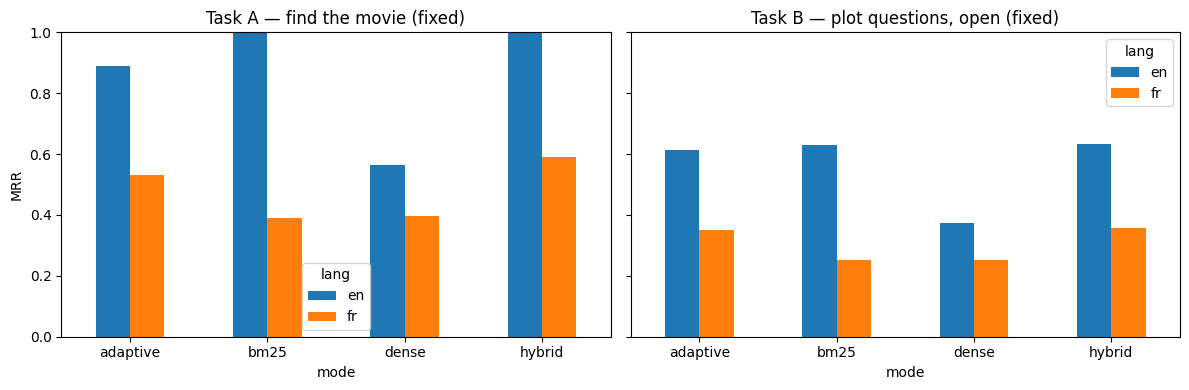

In [21]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
res_a.xs(best_chunking, level="chunking")["MRR"].unstack("lang").drop(index="adaptive+graph", errors="ignore") \
     .plot.bar(ax=axes[0], rot=0, title=f"Task A — find the movie ({best_chunking})")
res_b.xs(("open", best_chunking), level=("setting", "chunking"))["MRR"].unstack("lang") \
     .plot.bar(ax=axes[1], rot=0, title=f"Task B — plot questions, open ({best_chunking})")
axes[0].set_ylabel("MRR"); axes[0].set_ylim(0, 1); plt.tight_layout(); plt.show()

In [22]:
def show(query, k=5, chunking=None, mode="adaptive"):
    R = retrievers[chunking or best_chunking]
    print(f"Q: {query}\n   {analyze_query(query)}")
    ids, scores = R.search_movies(query, k=k, mode=mode)
    for mid, s in zip(ids, scores):
        m = movies.loc[mid]; print(f"   {s:.3f}  {m.title} ({m.year}) — {m.director}")

show("The movie where a weatherman keeps reliving the same day in a small town")
show("Un film où un homme se réveille chaque matin le même jour")

R = retrievers[best_chunking]
fails = [(r.title, r.query_en) for r in task_a.head(60).itertuples() if r.gold_movie not in R.search_movies(r.query_en)[0]]
pd.DataFrame(fails, columns=["gold title", "query"]).head(8)

Q: The movie where a weatherman keeps reliving the same day in a small town
   {'people': [], 'quoted': [], 'non_english': False, 'filters': {}, 'alpha': 0.6}
   0.948  Groundhog Day (1993) — Harold Ramis
   0.698  Small Town Story (1953) — Montgomery Tully
   0.674  Snow Day (2000) — Chris Koch
   0.672  Break of Day (1976) — Unknown
   0.667  Hold Back the Dawn (1941) — Mitchell Leisen
Q: Un film où un homme se réveille chaque matin le même jour
   {'people': [], 'quoted': [], 'non_english': True, 'filters': {}, 'alpha': 0.9}
   0.904   11:14 (2003) — Greg Marcks
   0.900  A Day (2017) — Cho Sun-ho
   0.829  It Happened Tomorrow (1944) — René Clair
   0.828  Every Day's a Holiday (1937) — A. Edward Sutherland
   0.825  The Beauty Inside (2015) — Baik (Baek Jong-yul)


,gold title,query
0,Anbu Thozhi,A film by L. G. Ravichandran. The movie where ...
1,One Good Cop,The movie where quinn tears up the confession ...
2,Susan Slade,"The movie where despite all this, someone and ..."
3,Adam Had Four Sons,"The movie where by then, the three older boys ..."
4,Quinceañera,A film by Richard Glatzer. The movie where her...
5,Marupadi,A film by V M Vinu. The movie where the film p...
6,The No Mercy Man,A film by Daniel Vance. The movie where though...
7,Rio 2,The movie where when he sees someone and his f...


## 8. Embedding model benchmark

In [23]:
MODELS_TO_TEST = [
    "nomic-ai/nomic-embed-text-v1.5",
    "intfloat/multilingual-e5-small",
    "intfloat/multilingual-e5-base",
]
bench = []
cs = chunk_sets[best_chunking]
for name in MODELS_TO_TEST:
    Rm = Retriever(cs, dense=DenseIndex([c["text"] for c in cs], model_name=name, tag=best_chunking))
    for lang in ("en", "fr"):
        a, b = eval_task_a(Rm, "dense", lang), eval_task_b(Rm, "dense", lang)
        bench.append({"model": name.split("/")[-1], "lang": lang, "A: MRR": a["MRR"], "A: R@10": a["R@10"],
                      "B: MRR": b["MRR"], "B: R@10": b["R@10"]})
pd.DataFrame(bench).set_index(["model", "lang"]).round(3)

modules.json:   0%|          | 0.00/255 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/140 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/71.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/58.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Batches:   0%|          | 0/552 [00:00<?, ?it/s]

embedded 35,281 chunks with intfloat/multilingual-e5-base in 603s (59 chunks/s)


A: MRR  A: R@10  B: MRR  B: R@10
model                 lang                                  
nomic-embed-text-v1.5 en     0.486    0.623   0.265    0.433
                      fr     0.099    0.167   0.084    0.140
multilingual-e5-small en     0.565    0.703   0.375    0.583
                      fr     0.396    0.500   0.253    0.410
multilingual-e5-base  en     0.503    0.637   0.424    0.580
                      fr     0.248    0.380   0.292    0.433

## 9. Grounded answers with citations

In [24]:
OLLAMA = "http://localhost:11434/api/generate"
LLM = "llama3.1:8b"
PROMPT = '''Answer the question using ONLY the movie plot passages below.
Cite the passages you use as [id]. If the answer isn't in the passages, say "I don't know".
Answer briefly, in the language of the question.

PASSAGES:
{context}

QUESTION: {question}
ANSWER:'''

def llm(prompt):
    try:
        r = requests.post(OLLAMA, json={"model": LLM, "prompt": prompt, "stream": False,
                                        "options": {"temperature": 0}}, timeout=180)
        return r.json()["response"].strip()
    except requests.exceptions.ConnectionError:
        return None

def answer(question, movie_ids=None, k=5):
    R = retrievers[best_chunking]
    allowed = np.isin(R.movie_of, movie_ids) if movie_ids is not None else None
    hits = R.search_chunks(question, k=k, allowed=allowed)
    context = "\n\n".join(f"[{c['chunk_id']}] {c['text']}" for c, _ in hits)
    text = llm(PROMPT.format(context=context, question=question))
    if text is None:
        return {"answer": "Ollama isn't running - start it with `ollama serve`.", "hits": hits, "bad_citations": []}
    cited = set(re.findall(r"\[(\d+#\d+)\]", text))
    return {"answer": text, "hits": hits, "bad_citations": sorted(cited - {c["chunk_id"] for c, _ in hits})}

def token_f1(pred, golds):
    p = tokenize(pred)
    best = 0.0
    for g in golds:
        g = tokenize(g); common = sum((Counter(p) & Counter(g)).values())
        if common:
            pr, rc = common / len(p), common / len(g); best = max(best, 2 * pr * rc / (pr + rc))
    return best

rows = []
for r in task_b.head(20).itertuples():
    out = answer(r.question, movie_ids=r.gold_movies)
    if out["answer"].startswith("Ollama isn't"):
        print(out["answer"]); break
    clean = re.sub(r"\[[^\]]+\]", "", out["answer"])
    rows.append({"question": r.question, "gold": r.answers[0], "answer": clean[:120],
                 "F1": round(token_f1(clean, r.answers), 2), "bad_citations": len(out["bad_citations"])})
if rows:
    df = pd.DataFrame(rows); print(f"mean F1 {df.F1.mean():.2f} | answers with invented citations: {(df.bad_citations > 0).sum()}"); df

Ollama isn't running - start it with `ollama serve`.


In [25]:
PARA = "Rewrite this as a short, vague question someone would ask when they half-remember a movie. No names.\n\n{q}\n\nRewrite:"
sample = task_a.head(50).copy()
para = [llm(PARA.format(q=q)) for q in sample.query_en]
if all(para):
    sample["query_en"] = para
    print(eval_task_a(retrievers[best_chunking], "adaptive", "en", subset=task_a.index.isin(sample.index)).round(3))

In [26]:
more_like_this(task_a.gold_movie.iloc[0])

,title,year,director,genre
movie_id,,,,
28146,Nizhalgal,1980,P. Bharathiraja,unknown
28462,Agni Paarvai,1992,P. Madhavan,unknown
28388,Durgaa,1990,Rama Narayanan,unknown
28301,Nayakan,1987,Mani Ratnam,unknown
28475,Bharathan,1992,S. D. Sabha,unknown
